<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Visión por Computadora 3D**
# **Clase 4, SIFT, Test de Lowe y RANSAC**



Pasos:
1. **SIFT**: encontrar keypoints y descriptores en cada imagen.
2. **Matching**: buscar, para cada descriptor, sus 2 vecinos más cercanos en la otra imagen.
3. **Test de Lowe**: quedarnos solo con los matches claramente mejores que el segundo candidato.
4. **RANSAC**: calcular la homografía ignorando los matches erróneos (outliers).
5. **Warp**: deformar una imagen para pegarla sobre la otra.



In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [7]:
def mostrar(img, titulo=''):
    """Muestra una imagen BGR (OpenCV) en el notebook."""
    plt.figure(figsize=(16, 8))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(titulo)
    plt.axis('off')
    plt.show()

**1.- Descargar imágenes de un dataset**

Usamos las imágenes de prueba de stitching de OpenCV ([opencv_extra](https://github.com/opencv/opencv_extra/tree/4.x/testdata/stitching)).


a1.png (1024, 800, 3)
a2.png (1024, 800, 3)
a3.png (1024, 800, 3)


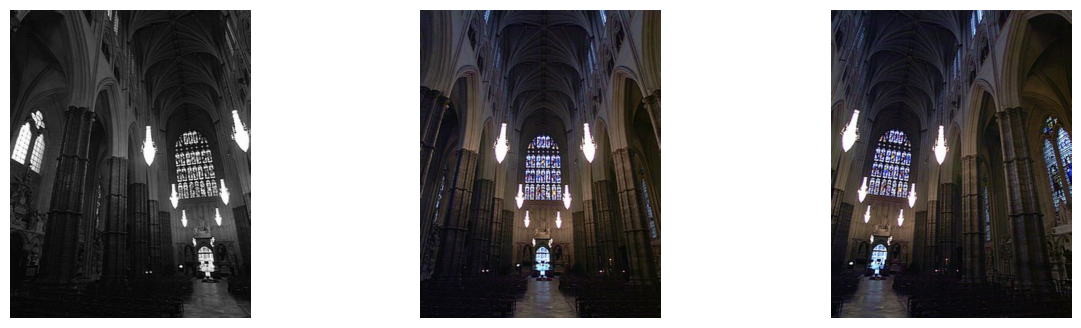

In [8]:
import urllib.request

DATASET = 'catedral'   # 'newspaper', 'puente' o 'catedral'

URL_BASE = 'https://raw.githubusercontent.com/opencv/opencv_extra/4.x/testdata/stitching/'
DATASETS = {
    'newspaper': ['newspaper1.jpg', 'newspaper2.jpg', 'newspaper3.jpg', 'newspaper4.jpg'],
    'puente': ['s1.jpg', 's2.jpg'],
    'catedral':  ['a1.png', 'a2.png', 'a3.png'],
}

imagenes = []
for nombre in DATASETS[DATASET]:
    urllib.request.urlretrieve(URL_BASE + nombre, nombre)   # descarga el archivo
    img = cv2.imread(nombre)

    # Reducimos el tamaño para que SIFT vaya más rápido
    escala = 800 / img.shape[1]
    img = cv2.resize(img, None, fx=escala, fy=escala)
    imagenes.append(img)
    print(nombre, img.shape)

# Vista previa de las imágenes sueltas
fig, ejes = plt.subplots(1, len(imagenes), figsize=(5 * len(imagenes), 4))
for eje, img in zip(ejes, imagenes):
    eje.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    eje.axis('off')
plt.show()

**2. Función para unir dos imágenes**

In [9]:
sift = cv2.SIFT_create() # detector de keypoints SIFT
matcher = cv2.BFMatcher() # comparador por fuerza bruta (distancia L2)

def unir(img_izq, img_der, ver_matches=True):
    #SIFT: keypoints y descriptores (se calculan en escala de grises)
    gris1 = cv2.cvtColor(img_izq, cv2.COLOR_BGR2GRAY)
    gris2 = cv2.cvtColor(img_der, cv2.COLOR_BGR2GRAY)
    kp1, des1 = sift.detectAndCompute(gris1, None)
    kp2, des2 = sift.detectAndCompute(gris2, None)
    print(f"Keypoints: {len(kp1)} y {len(kp2)}")

    #Matching: los 2 vecinos más cercanos de cada descriptor
    matches = matcher.knnMatch(des2, des1, k=2)

    #Test de Lowe
    # Un match es bueno si el mejor candidato (m) es bastante más cercano
    # que el segundo (n). Si se parecen, el punto es ambiguo y se descarta.
    buenos = []
    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            buenos.append(m)
    print(f"Matches: {len(matches)} -> tras test de Lowe: {len(buenos)}")

    if len(buenos) < 4:   # una homografía necesita al menos 4 puntos
        raise Exception("No hay suficientes coincidencias entre las imágenes")

    # Coordenadas de los puntos emparejados
    pts_der = np.float32([kp2[m.queryIdx].pt for m in buenos])
    pts_izq = np.float32([kp1[m.trainIdx].pt for m in buenos])

    # RANSAC: homografía robusta
    # Prueba muchas combinaciones de 4 puntos y se queda con la homografía
    # que más puntos explica con error < 5 px. Los demás son outliers.
    H, mascara = cv2.findHomography(pts_der, pts_izq, cv2.RANSAC, 5.0)
    print(f"Inliers RANSAC: {int(mascara.sum())} de {len(buenos)}")

    if ver_matches:   # dibuja solo los matches que RANSAC aceptó (inliers)
        vis = cv2.drawMatches(img_der, kp2, img_izq, kp1, buenos, None,
                              matchesMask=mascara.ravel().tolist(), flags=2)
        mostrar(vis, "Matches tras Lowe + RANSAC (inliers)")

    #Warp: proyectar la imagen derecha en el plano de la izquierda
    h1, w1 = img_izq.shape[:2]
    h2, w2 = img_der.shape[:2]

    # Calculamos dónde caen las esquinas de ambas imágenes para saber
    # qué tamaño debe tener el lienzo final
    esq_der = np.float32([[0, 0], [w2, 0], [w2, h2], [0, h2]]).reshape(-1, 1, 2)
    esq_der = cv2.perspectiveTransform(esq_der, H)
    esq_izq = np.float32([[0, 0], [w1, 0], [w1, h1], [0, h1]]).reshape(-1, 1, 2)
    todas = np.concatenate([esq_izq, esq_der])
    x_min, y_min = np.int32(todas.min(axis=0).ravel())
    x_max, y_max = np.int32(todas.max(axis=0).ravel())

    # Traslación para que no queden coordenadas negativas
    T = np.array([[1, 0, -x_min], [0, 1, -y_min], [0, 0, 1]], dtype=np.float64)

    # Deformamos la imagen derecha sobre el lienzo grande
    resultado = cv2.warpPerspective(img_der, T @ H, (x_max - x_min, y_max - y_min))

    # Pegamos la imagen izquierda encima (sin deformar, solo trasladada)
    resultado[-y_min:h1 - y_min, -x_min:w1 - x_min] = img_izq
    return resultado

**3.- Unir todas las imágenes**
Se une la 1ª con la 2ª, el resultado con la 3ª, y así sucesivamente...


=== Uniendo imagen 2 ===
Keypoints: 3246 y 3475
Matches: 3475 -> tras test de Lowe: 1169
Inliers RANSAC: 1058 de 1169


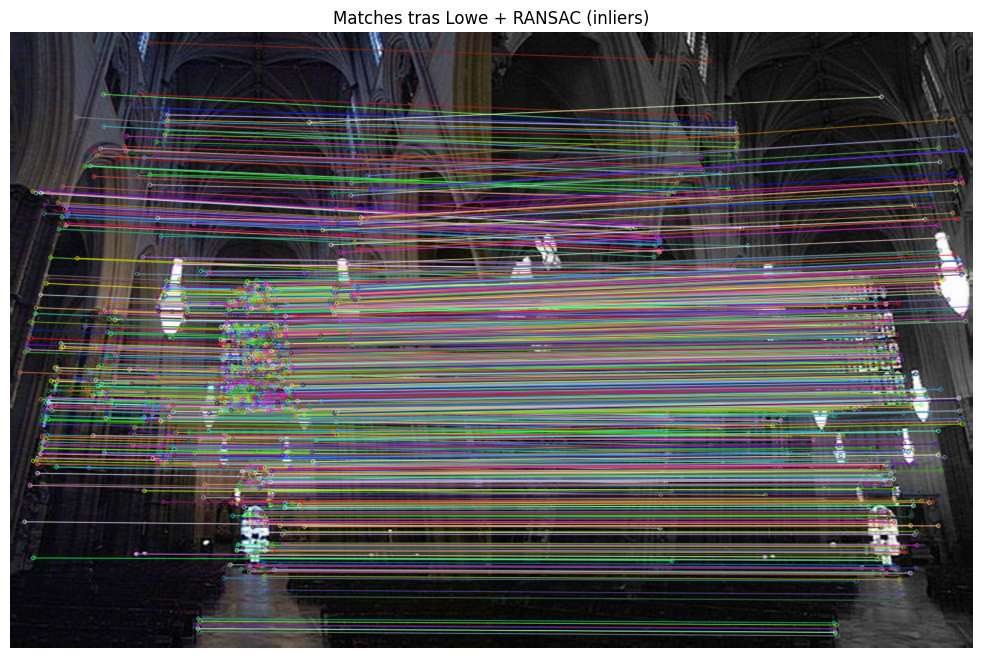


=== Uniendo imagen 3 ===
Keypoints: 4083 y 3972
Matches: 3972 -> tras test de Lowe: 995
Inliers RANSAC: 863 de 995


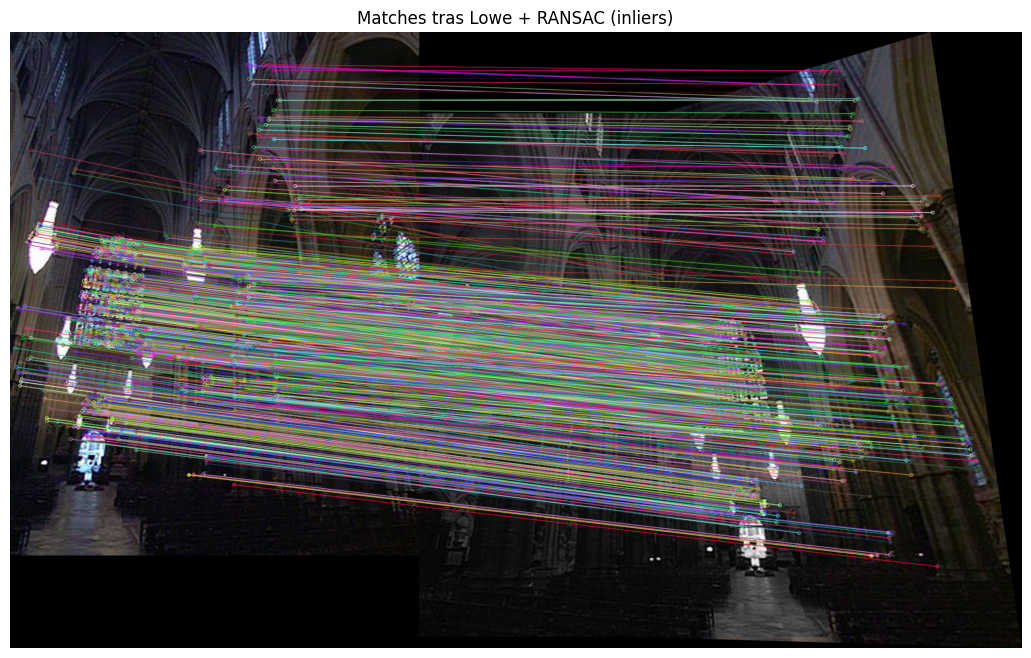

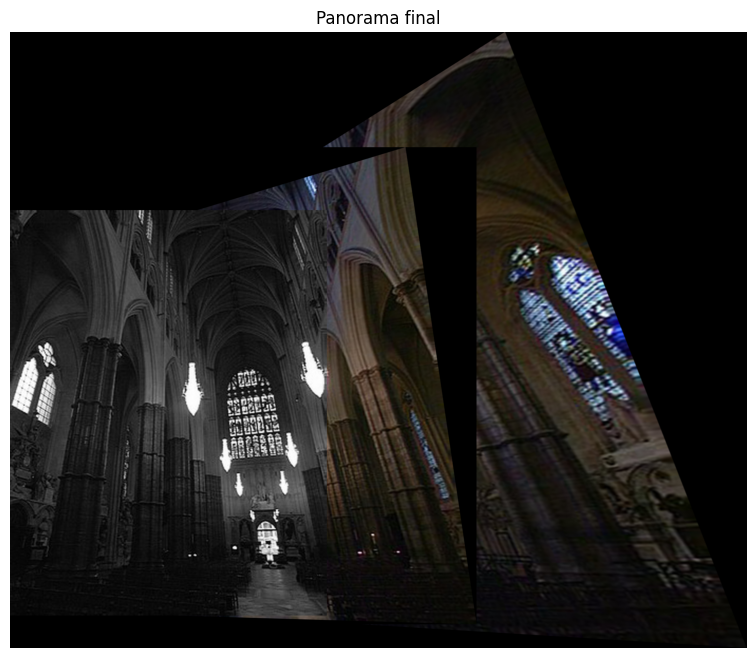

In [10]:
panorama = imagenes[0]
for i in range(1, len(imagenes)):
    print(f"\n=== Uniendo imagen {i+1} ===")
    panorama = unir(panorama, imagenes[i])

# Quitamos los bordes negros sobrantes
gris = cv2.cvtColor(panorama, cv2.COLOR_BGR2GRAY)
x, y, w, h = cv2.boundingRect(cv2.findNonZero(gris))
panorama = panorama[y:y+h, x:x+w]

mostrar(panorama, "Panorama final")